# Indian Legal AI: evaluation

Measures the system as it is deployed: the four local models served by llama-server (Q4_K_M GGUFs), the LanceDB retrieval stack, the router and the drafting classifier.

| Part | Question it answers | Data |
|---|---|---|
| 1. Model quality (no retrieval) | Did fine-tuning help, for 4B and 8B? Does the 4-bit deployment keep the gains measured on the HPC? | The 100 held-out questions of the reference benchmark (`to_finetune/data/val.jsonl`) |
| 2. Retrieval | Does the right statute section or judgment reach the model? How much does the cross-encoder add? | 73 statute questions with verified target sections, 18 landmark-case questions |
| 3. Routing and drafting | Are questions sent to the right evidence source? Are drafting requests recognised and given the right format? | 35 routing and 19 drafting requests, plus the 91 corpus questions |
| 4. Evidence thresholds | Do the rerank-score cut-offs in `src/pipeline.py` (3 and -2) separate covered from uncovered questions? | Scores from part 2 plus off-topic and advice questions |
| 5. End-to-end answers | Base vs fine-tuned, with and without retrieval: is the right provision cited, and is every cited section in the evidence? | The 91 corpus questions |

Everything is written to `notebooks/results/`: per-question CSVs, summary tables, figures and `report.md`. The labelled questions live in `notebooks/benchmark/legal_benchmark.json`.

**Running it.** Use the project's `.venv` kernel and run all cells. A full run takes about 1.5 hours on an RTX 5060 Laptop GPU (8 GB); `QUICK = True` takes about 15 minutes. Generations are cached in `results/cache/`, so an interrupted run resumes where it stopped. Needs the GGUFs and llama-server from `setup.sh`, and the RAG index. Perplexity (part 1b) also needs the base weights and adapters (`setup.sh --with-hf-weights`) and is skipped without them.

## 0. Configuration

In [1]:
QUICK = False                  # True: 20 held-out questions, 18 corpus questions (about 15 minutes)
SEED = 42

MODELS = [
    "Qwen3-VL-4B-Instruct",
    "Qwen3-VL-4B-Legal (Fine-Tuned)",
    "Qwen3-VL-8B-Instruct",
    "Qwen3-VL-8B-Legal (Fine-Tuned)",
]

N_HELDOUT = 20 if QUICK else 100      # part 1: same 100 questions as to_finetune/evaluate.py
CLOSED_BOOK_MAX_TOKENS = 200          # part 1: same budget as the reference benchmark
ANSWER_MAX_TOKENS = 768               # part 5: the app allows 1500; capped to keep the run near 1.5 h
N_CORPUS = (12, 6) if QUICK else None # part 5: (statute, precedent) questions to use; None = all 91

RUN = {
    "model_quality": True,
    "perplexity": "auto",   # "auto": only if base weights + adapters are on disk; True / False to force
    "retrieval": True,
    "routing": True,
    "rag_answers": True,
    "judge": False,         # optional Gemini grading of part 5 answers (needs GEMINI_API_KEY, costs API calls)
}
FRESH = False  # True: discard cached generations in results/cache and regenerate everything

## Setup

In [2]:
import importlib.util, json, math, os, platform, re, subprocess, sys, time, urllib.request
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)  # src/ resolves data/lancedb and Models/ relative to the project root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "notebooks" / "results"
CACHE = RESULTS / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from tqdm import tqdm

from src import llm, pipeline, routing
from src.agent import is_drafting_request
from src.generation import build_prompt
from src.legal_formats import classify_document
from src.reranking import Reranker
from src.retrieval import LegalRetriever

# The reference benchmark's metric code, so ROUGE / BLEU / citation numbers are comparable with FINETUNING_INFO.md
_spec = importlib.util.spec_from_file_location("ft_evaluate", ROOT / "to_finetune" / "evaluate.py")
ref = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(ref)

BENCH = json.loads((ROOT / "notebooks" / "benchmark" / "legal_benchmark.json").read_text(encoding="utf-8"))
ACTS = BENCH["acts"]

missing = [m for m in MODELS if not llm._gguf_path(m)]
MODELS = [m for m in MODELS if m not in missing]
if missing:
    print("Skipping (GGUF or llama-server not found):", missing)
assert MODELS, "No local models available: run setup.sh first."

pd.set_option("display.max_colwidth", 80)
REPORT = {}  # markdown sections collected for results/report.md
print("Models:", MODELS)
print("Benchmark:", {k: len(v) for k, v in BENCH.items() if isinstance(v, list)})

d:\Drive E\Ishan\Plaksha\IDEA for hackathon\RAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Models: ['Qwen3-VL-4B-Instruct', 'Qwen3-VL-4B-Legal (Fine-Tuned)', 'Qwen3-VL-8B-Instruct', 'Qwen3-VL-8B-Legal (Fine-Tuned)']
Benchmark: {'statute': 73, 'precedent': 18, 'routing': 35, 'drafting': 19}


In [3]:
def _cmd(args):
    try:
        return subprocess.run(args, stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True, timeout=30).stdout.strip()
    except Exception as e:
        return f"unavailable ({type(e).__name__})"

def _llama_version():
    try:
        out = subprocess.run([str(llm.LLAMA_SERVER_EXE), "--version"], capture_output=True, text=True, timeout=30)
        return next((l for l in (out.stdout + out.stderr).splitlines() if l.startswith("version")), "unknown")
    except Exception as e:
        return f"unavailable ({type(e).__name__})"

ENV = {
    "run_started": time.strftime("%Y-%m-%d %H:%M:%S"),
    "quick": QUICK,
    "seed": SEED,
    "models": {m: {"gguf": Path(llm._gguf_path(m)).name, "size_gb": round(Path(llm._gguf_path(m)).stat().st_size / 1e9, 2)} for m in MODELS},
    "llama_server": _llama_version(),
    "context_window": llm.LLAMA_CTX,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "nvidia_driver": _cmd(["nvidia-smi", "--query-gpu=driver_version,memory.total", "--format=csv,noheader"]),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "os": platform.platform(),
    "git_commit": _cmd(["git", "rev-parse", "--short", "HEAD"]),
}
(RESULTS / "environment.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")
ENV

{'run_started': '2026-10-27 21:06:45',
 'quick': False,
 'seed': 42,
 'models': {'Qwen3-VL-4B-Instruct': {'gguf': 'qwen3-vl-4b-instruct.Q4_K_M.gguf',
   'size_gb': 2.5},
  'Qwen3-VL-4B-Legal (Fine-Tuned)': {'gguf': 'legal-qwen3-vl-4b.Q4_K_M.gguf',
   'size_gb': 2.5},
  'Qwen3-VL-8B-Instruct': {'gguf': 'qwen3-vl-8b-instruct.Q4_K_M.gguf',
   'size_gb': 5.03},
  'Qwen3-VL-8B-Legal (Fine-Tuned)': {'gguf': 'legal-qwen3-vl-8b.Q4_K_M.gguf',
   'size_gb': 5.03}},
 'llama_server': 'version: 0.7.0-dev (build 11836, commit f5027fb21)',
 'context_window': 8192,
 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU',
 'nvidia_driver': '616.92, 8151 MiB',
 'python': '3.12.10',
 'torch': '2.14.1+cu132',
 'os': 'Windows-11-10.0.26300-SP0',
 'git_commit': 'c91b540'}

### Helpers

- **Generation** goes through the same llama-server and sampling settings as the app (temperature 0.2, top-p 0.9, repetition penalty 1.1) with a fixed seed, and strips the training-data meta-commentary the same way `src/llm.py` does.
- **Cache:** each generation is appended to `results/cache/*.jsonl` and reused on the next run.
- **Citation parsing:** `cited_sections` pulls section numbers out of an answer ("Section 103(1)", "Ss. 437 and 439", "498-A" -> `103`, `437`, `439`, `498A`). An answer cites the correct provision when it names a target section *and* the target Act (by name or abbreviation), since section numbers repeat across Acts.

In [4]:
SAMPLING = dict(temperature=0.2, top_p=0.9, repeat_penalty=1.1)  # src/llm.py and to_finetune/evaluate.py

def size_of(m): return "8B" if "8B" in m else "4B"
def variant_of(m): return "Fine-tuned" if "Legal" in m else "Base"
def short(m): return f"{size_of(m)} {variant_of(m)}"


class Cache:
    """Append-only JSONL store, so long runs resume after an interruption."""
    def __init__(self, name):
        self.path = CACHE / f"{name}.jsonl"
        if FRESH and self.path.exists():
            self.path.unlink()
        self.data = {}
        if self.path.exists():
            for line in self.path.open(encoding="utf-8"):
                if line.strip():
                    r = json.loads(line)
                    self.data[r["key"]] = r["value"]

    def get(self, key):
        return self.data.get(key)

    def put(self, key, value):
        self.data[key] = value
        with self.path.open("a", encoding="utf-8") as f:
            f.write(json.dumps({"key": key, "value": value}, ensure_ascii=False) + "\n")


def generate(model, prompt, max_tokens):
    """One completion from llama-server, with its own token counts and timings."""
    llm._ensure_llama_server(llm._gguf_path(model))  # starts it, or switches the loaded model
    body = {"messages": [{"role": "user", "content": prompt}], "max_tokens": max_tokens, "seed": SEED, "stream": False, **SAMPLING}
    req = urllib.request.Request(f"{llm.LLAMA_SERVER_URL}/v1/chat/completions", data=json.dumps(body).encode("utf-8"),
                                 headers={"Content-Type": "application/json"})
    t0 = time.time()
    with urllib.request.urlopen(req, timeout=900) as r:
        d = json.loads(r.read())
    choice, tm = d["choices"][0], d.get("timings", {})
    return {
        "text": llm._strip_meta(choice["message"].get("content") or "").strip(),
        "finish": choice.get("finish_reason"),
        "prompt_tokens": tm.get("prompt_n"),
        "completion_tokens": tm.get("predicted_n"),
        "gen_tok_s": tm.get("predicted_per_second"),
        "prompt_tok_s": tm.get("prompt_per_second"),
        "latency_s": round(time.time() - t0, 3),
    }


def run_generations(cache, items, max_tokens, desc):
    """items: [(key, prompt)]. Models are the outer loop so each one is loaded once."""
    out = {}
    for m in MODELS:
        todo = [(k, p) for k, p in items if cache.get(f"{m}|{k}") is None]
        for k, p in tqdm(todo, desc=f"{desc}: {short(m)}"):
            cache.put(f"{m}|{k}", generate(m, p, max_tokens))
        out.update({(m, k): cache.get(f"{m}|{k}") for k, _ in items})
    return out


def paired_bootstrap(a, b, n=5000, seed=SEED):
    """Mean of (b - a) over paired questions with a 95% bootstrap interval."""
    d = np.asarray(b, float) - np.asarray(a, float)
    rng = np.random.default_rng(seed)
    boots = rng.choice(d, size=(n, len(d)), replace=True).mean(axis=1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def md_table(df, index=True, fmt="{:.2f}"):
    d = df.reset_index() if index else df
    cell = lambda v: "" if v is None or (isinstance(v, float) and math.isnan(v)) else (fmt.format(v) if isinstance(v, (float, np.floating)) else str(v))
    rows = ["| " + " | ".join(map(str, d.columns)) + " |", "|" + "|".join("---" for _ in d.columns) + "|"]
    rows += ["| " + " | ".join(cell(v) for v in r) + " |" for r in d.itertuples(index=False)]
    return "\n".join(rows)


def save_csv(df, name, index=False):
    df.to_csv(RESULTS / name, index=index, encoding="utf-8")


# ---- citations in answers ---------------------------------------------------------------
_SEC = re.compile(
    r"(?<![A-Za-z])(?:sections?|secs?\.?|ss?\.|u/s\.?)\s*"
    r"(\d+(?:-?[A-Z]{1,2})?(?:\s*\([0-9a-z]+\))*(?:\s*(?:,|and|&|/|or|to)\s*\d+(?:-?[A-Z]{1,2})?(?:\s*\([0-9a-z]+\))*)*)",
    re.I,
)
_NUM = re.compile(r"\d+(?:-?[A-Z]{1,2})?(?![A-Za-z])", re.I)

def norm_sec(s):
    return str(s).replace("-", "").replace(" ", "").upper()

def cited_sections(text):
    out = set()
    for m in _SEC.finditer(text or ""):
        group = re.sub(r"\([0-9a-z]+\)", "", m.group(1))
        out |= {norm_sec(n) for n in _NUM.findall(group)}
    return out

def mentions_act(text, key):
    return any(re.search(rf"(?<![A-Za-z]){re.escape(a)}(?![A-Za-z])", text or "", re.I) for a in ACTS[key]["aliases"])

def cites_provision(text, targets):
    secs = cited_sections(text)
    return any(norm_sec(s) in secs and mentions_act(text, k) for k, s in targets)


# ---- relevance of retrieved chunks ------------------------------------------------------
def _title_ok(title, key):
    return any(t.lower() in (title or "").lower() for t in ACTS[key]["titles"])

def statute_hit(c, targets):
    return c.get("source_type") == "act" and any(_title_ok(c.get("act_title"), k) and norm_sec(c.get("section_number")) == norm_sec(s) for k, s in targets)

def act_hit(c, targets):
    return c.get("source_type") == "act" and any(_title_ok(c.get("act_title"), k) for k, _ in targets)

def precedent_hit(c, item):
    text = c.get("text") or ""
    return bool(re.search(item["pattern"], text, re.I)) and any(k.lower() in text.lower() for k in item["keywords"])

def first_rank(chunks, pred, k=None):
    for i, c in enumerate(chunks[:k] if k else chunks, 1):
        if pred(c):
            return i
    return None

assert cited_sections("Under Section 103(1) BNS and Ss. 437 and 439 CrPC, or s. 498-A") == {"103", "437", "439", "498A"}
assert cites_provision("Section 302 of the Indian Penal Code", [["IPC", "302"]]) and not cites_provision("Section 302 BNS", [["IPC", "302"]])

In [5]:
# Chart style: reference palette from the dataviz guidance (validated: categorical slots 1-3 pass all-pairs CVD checks)
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # blue, orange, aqua (aqua is < 3:1 on white: every chart carries value labels)
NEUTRAL = "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"], "savefig.facecolor": INK["surface"],
    "font.family": ["Segoe UI", "system-ui", "DejaVu Sans"], "font.size": 9,
    "axes.edgecolor": INK["axis"], "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": INK["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titlecolor": INK["primary"], "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelcolor": INK["secondary"], "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
    "legend.frameon": False, "legend.fontsize": 8.5, "text.color": INK["primary"],
})

def label_bars(ax, bars, fmt="{:.1f}"):
    ax.bar_label(bars, labels=[fmt.format(b.get_height()) for b in bars], padding=2, fontsize=7.5, color=INK["secondary"])

def grouped_bars(ax, groups, series, values, fmt="{:.1f}", width=0.36):
    """values[s][g]; groups on x, one bar per series, 2px surface gap between bars."""
    x = np.arange(len(groups))
    offs = (np.arange(len(series)) - (len(series) - 1) / 2) * width
    for i, s in enumerate(series):
        bars = ax.bar(x + offs[i], [values[s].get(g, np.nan) for g in groups], width, label=s,
                      color=SERIES[i], edgecolor=INK["surface"], linewidth=2)
        label_bars(ax, bars, fmt)
    ax.set_xticks(x, groups)
    ax.margins(y=0.15)

def save_fig(fig, name):
    fig.savefig(RESULTS / name, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved", f"notebooks/results/{name}")

## 1. Model quality without retrieval: base vs fine-tuned

The same protocol as `to_finetune/evaluate.py`: the first 100 questions of `val.jsonl` that never appear in `train.jsonl`, a 200-token answer, and ROUGE / BLEU / legal-citation overlap with the reference answer. The difference is the deployment: these are the Q4_K_M GGUFs the app serves, not bf16 weights on the HPC. Overlap metrics reward answers worded like the training data, which is what fine-tuning teaches, so read them alongside parts 2 and 5.

In [6]:
val = [json.loads(l) for l in open(ROOT / "to_finetune/data/val.jsonl", encoding="utf-8") if l.strip()]
train_prompts = {json.loads(l)["messages"][0]["content"].strip() for l in open(ROOT / "to_finetune/data/train.jsonl", encoding="utf-8") if l.strip()}
heldout = [s for s in val if s["messages"][0]["content"].strip() not in train_prompts][:N_HELDOUT]
print(f"{len(heldout)} held-out questions (none in train.jsonl). Example: {heldout[0]['messages'][0]['content']!r}")

100 held-out questions (none in train.jsonl). Example: 'When was the Foreign Exchange Regulation Act passed and what is its act number?'


In [7]:
if RUN["model_quality"]:
    cb_cache = Cache(f"closed_book_t{CLOSED_BOOK_MAX_TOKENS}_seed{SEED}")
    cb_gens = run_generations(cb_cache, [(s["id"], s["messages"][0]["content"]) for s in heldout], CLOSED_BOOK_MAX_TOKENS, "Held-out")

    rows = []
    for s in heldout:
        q, gold = s["messages"][0]["content"], s["messages"][1]["content"].strip()
        for m in MODELS:
            g = cb_gens[(m, s["id"])]
            rw, hw = ref.tokenize_words(gold), ref.tokenize_words(g["text"])
            rows.append({
                "id": s["id"], "model": m, "size": size_of(m), "variant": variant_of(m),
                **ref.compute_rouge(rw, hw), **ref.compute_bleu(rw, hw), **ref.compute_legal_citation_metrics(gold, g["text"]),
                "legal_terms": ref.compute_legal_terminology_density(g["text"]),
                "completion_tokens": g["completion_tokens"], "gen_tok_s": g["gen_tok_s"], "latency_s": g["latency_s"],
                "hit_max_tokens": g["finish"] == "length", "question": q, "gold": gold, "answer": g["text"],
            })
    mq = pd.DataFrame(rows)
    save_csv(mq, "part1_heldout_per_question.csv")

    MQ_COLS = ["rouge_1", "rouge_2", "rouge_l", "bleu_1", "bleu_2", "bleu_4", "citation_recall", "citation_precision",
               "citation_f1", "legal_terms", "completion_tokens", "gen_tok_s", "latency_s", "hit_max_tokens"]
    mq_summary = mq.groupby("model", sort=False)[MQ_COLS].mean().reindex(MODELS)
    mq_summary["hit_max_tokens"] *= 100
    mq_summary.index = [short(m) for m in mq_summary.index]
    save_csv(mq_summary, "part1_heldout_summary.csv", index=True)
    display(mq_summary.round(2))

Held-out: 4B Base: 0it [00:00, ?it/s]
Held-out: 4B Fine-tuned: 0it [00:00, ?it/s]
Held-out: 8B Base: 0it [00:00, ?it/s]
Held-out: 8B Fine-tuned: 0it [00:00, ?it/s]


,rouge_1,rouge_2,rouge_l,bleu_1,bleu_2,bleu_4,citation_recall,citation_precision,citation_f1,legal_terms,completion_tokens,gen_tok_s,latency_s,hit_max_tokens
4B Base,28.05,9.75,17.09,11.84,6.85,2.87,79.74,75.91,74.85,0.71,198.80,102.42,1.98,98.0
4B Fine-tuned,32.22,15.05,21.14,12.18,8.05,4.52,79.68,79.10,76.79,0.45,180.14,101.81,1.81,84.0
8B Base,28.10,9.90,16.89,11.73,6.71,2.89,79.91,76.15,74.86,0.79,199.14,64.13,3.15,98.0
8B Fine-tuned,32.22,15.28,21.23,12.52,8.43,4.80,78.24,80.60,77.11,0.55,178.38,64.20,2.82,82.0


In [8]:
if RUN["model_quality"]:
    # Fine-tuned minus base on the same questions, with 95% bootstrap intervals
    deltas = []
    for size in sorted({size_of(m) for m in MODELS}):
        pair = [m for m in MODELS if size_of(m) == size]
        if len(pair) != 2:
            continue
        base, ft = sorted(pair, key=lambda m: variant_of(m) != "Base")
        a = mq[mq.model == base].set_index("id")
        b = mq[mq.model == ft].set_index("id").loc[a.index]
        for col in ["rouge_1", "rouge_2", "rouge_l", "bleu_4", "citation_f1", "legal_terms"]:
            d, lo, hi = paired_bootstrap(a[col], b[col])
            deltas.append({"size": size, "metric": col, "base": a[col].mean(), "fine_tuned": b[col].mean(),
                           "difference": d, "ci95_low": lo, "ci95_high": hi, "significant": lo > 0 or hi < 0})
    mq_delta = pd.DataFrame(deltas)
    save_csv(mq_delta, "part1_finetune_effect.csv")
    display(mq_delta.round(2))

,size,metric,base,fine_tuned,difference,ci95_low,ci95_high,significant
0,4B,rouge_1,28.05,32.22,4.17,2.72,5.51,True
1,4B,rouge_2,9.75,15.05,5.31,4.29,6.28,True
2,4B,rouge_l,17.09,21.14,4.05,2.98,5.05,True
3,4B,bleu_4,2.87,4.52,1.64,1.05,2.25,True
4,4B,citation_f1,74.85,76.79,1.94,-3.19,7.22,False
5,4B,legal_terms,0.71,0.45,-0.26,-0.50,-0.03,True
6,8B,rouge_1,28.10,32.22,4.11,2.25,5.93,True
7,8B,rouge_2,9.90,15.28,5.38,3.98,6.70,True
8,8B,rouge_l,16.89,21.23,4.33,3.03,5.68,True
9,8B,bleu_4,2.89,4.80,1.91,0.98,2.92,True


findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: 

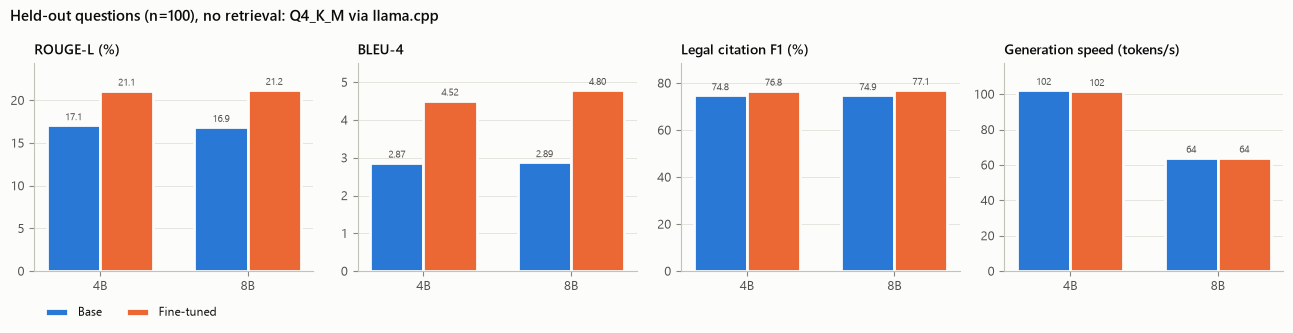

Saved notebooks/results/fig1_model_quality.png


In [9]:
if RUN["model_quality"]:
    sizes = [s for s in ["4B", "8B"] if any(size_of(m) == s for m in MODELS)]
    panels = [("rouge_l", "ROUGE-L (%)", "{:.1f}"), ("bleu_4", "BLEU-4", "{:.2f}"),
              ("citation_f1", "Legal citation F1 (%)", "{:.1f}"), ("gen_tok_s", "Generation speed (tokens/s)", "{:.0f}")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
    for ax, (col, title, fmt) in zip(axes, panels):
        vals = {v: {size_of(m): mq[mq.model == m][col].mean() for m in MODELS if variant_of(m) == v} for v in ["Base", "Fine-tuned"]}
        grouped_bars(ax, sizes, ["Base", "Fine-tuned"], vals, fmt)
        ax.set_title(title)
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
    fig.suptitle(f"Held-out questions (n={len(heldout)}), no retrieval: Q4_K_M via llama.cpp", x=0.01, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout()
    save_fig(fig, "fig1_model_quality.png")

**Against the reference benchmark.** `to_finetune/FINETUNING_INFO.md` section 8 reports the same questions run in bf16 on the HPC. The app's 4B adapter is the 2-epoch run (`Models/legal-lora-vl-4b-adapter/train_config.json`), so that is the reference row used. Sampling is stochastic, so expect differences of a point or so even with the same weights; larger gaps would come from 4-bit quantization.

In [10]:
REFERENCE_BF16 = {  # FINETUNING_INFO.md tables 8.1 and 8.2
    "4B Base":       {"rouge_1": 27.34, "rouge_2": 9.33,  "rouge_l": 16.86, "bleu_4": 2.74, "citation_recall": 81.11, "citation_f1": 75.97, "ppl": 3.84},
    "4B Fine-tuned": {"rouge_1": 31.89, "rouge_2": 14.54, "rouge_l": 20.79, "bleu_4": 4.34, "citation_recall": 78.52, "citation_f1": 76.60, "ppl": 2.14},
    "8B Base":       {"rouge_1": 27.40, "rouge_2": 9.52,  "rouge_l": 16.85, "bleu_4": 2.90, "citation_recall": 80.17, "citation_f1": 76.19, "ppl": 3.63},
    "8B Fine-tuned": {"rouge_1": 31.33, "rouge_2": 13.98, "rouge_l": 20.54, "bleu_4": 4.11, "citation_recall": 74.51, "citation_f1": 74.60, "ppl": 2.06},
}
if RUN["model_quality"]:
    cmp_rows = []
    for name, refv in REFERENCE_BF16.items():
        if name not in mq_summary.index:
            continue
        for col in ["rouge_1", "rouge_2", "rouge_l", "bleu_4", "citation_recall", "citation_f1"]:
            cmp_rows.append({"model": name, "metric": col, "reference_bf16_hpc": refv[col],
                             "this_run_q4_k_m": mq_summary.loc[name, col], "difference": mq_summary.loc[name, col] - refv[col]})
    ref_cmp = pd.DataFrame(cmp_rows)
    save_csv(ref_cmp, "part1_vs_reference.csv")
    display(ref_cmp.pivot(index="model", columns="metric", values="difference").round(2))

metric,bleu_4,citation_f1,citation_recall,rouge_1,rouge_2,rouge_l
model,,,,,,
4B Base,0.13,-1.12,-1.37,0.71,0.42,0.23
4B Fine-tuned,0.18,0.19,1.16,0.33,0.51,0.35
8B Base,-0.01,-1.33,-0.26,0.70,0.38,0.04
8B Fine-tuned,0.69,2.51,3.73,0.89,1.30,0.69


In [11]:
if RUN["model_quality"]:
    lines = ["# Held-out examples\n"]
    for s in heldout[:3]:
        lines.append(f"## {s['messages'][0]['content']}\n\n**Reference answer:** {s['messages'][1]['content'][:700]}\n")
        for m in MODELS:
            lines.append(f"**{short(m)}:** {cb_gens[(m, s['id'])]['text'][:700]}\n")
    (RESULTS / "examples_heldout.md").write_text("\n".join(lines), encoding="utf-8")
    display(Markdown("\n".join(lines[:1 + 1 + len(MODELS)])))

# Held-out examples

## When was the Foreign Exchange Regulation Act passed and what is its act number?

**Reference answer:** The Foreign Exchange Regulation Act was passed in 1973, and its act number is 12. This legislation, which aims to regulate the exchange of foreign currency, was enacted to ensure the stability and security of the country's financial system. The act number 12 signifies its importance and relevance in the context of foreign exchange regulation, which is crucial for managing international trade and financial transactions. The act was passed to address the complexities and challenges associated with the fluctuating value of currencies, ensuring that the country's economy remains stable and predictable. The Foreign Exchange Regulation Act is a significant piece of legislation that has shaped the 

**4B Base:** The **Foreign Exchange Regulation Act (FERA)** was passed in **1973**. It received the **Act No. 24 of 1973**.

This legislation was enacted by the Government of India to regulate foreign exchange transactions, control the flow of foreign currency into and out of the country, and ensure that foreign exchange is used for legitimate purposes. The Act was later replaced in part by the **Foreign Exchange Management Act (FEMA)** in 1999, which came into force on April 1, 1999.

So, to summarize:

- **Year passed**: 1973  
- **Act number**: **No. 24 of 1973**

It is important to note that while FERA was a landmark law in India’s foreign exchange policy, it has since been superseded by FEMA under t

**4B Fine-tuned:** The Foreign Exchange Regulation Act was passed in 1947, but it's not mentioned in the provided context. The act number for this legislation can be found by referring to official government documents or legal databases that track Indian laws.

**8B Base:** The **Foreign Exchange Regulation Act (FERA)** was passed on **April 1, 1979**, in India.

Its official **act number** is **Act No. 2 of 1979**.

This legislation was enacted to regulate foreign exchange transactions and control the inflow and outflow of foreign currency in India. It was later replaced by the **Foreign Exchange Management Act (FEMA)**, which came into force on **June 1, 1994**, to liberalize and modernize foreign exchange regulations.

**Note**: FERA is now obsolete; FEMA governs foreign exchange matters in India today.

**8B Fine-tuned:** The Foreign Exchange Regulation Act was passed in 1973 and its act number is 18.


### 1b. Perplexity on the reference answers (optional)

How likely each model finds the held-out reference answer: the clearest signal that fine-tuning moved the models towards the target style. llama-server does not return probabilities for given text, so this uses transformers with the base weights in 4-bit NF4 and the LoRA adapter, the same masking as the reference benchmark (loss on the answer tokens only). It stops llama-server first to free the GPU.

In [12]:
def _hf_available(m):
    adapter = llm.ADAPTER_PATHS.get(m)
    return llm.AVAILABLE_MODELS[m].exists() and (adapter is None or adapter.exists())

run_ppl = RUN["perplexity"] is True or (RUN["perplexity"] == "auto" and torch.cuda.is_available() and all(_hf_available(m) for m in MODELS))
ppl = None
if not run_ppl:
    print("Skipped: needs a GPU plus base weights and adapters (setup.sh --with-hf-weights).")
else:
    from transformers import AutoModelForImageTextToText, AutoProcessor, BitsAndBytesConfig
    import gc
    from peft import PeftModel

    def _template(processor, msgs, gen):
        try:
            return processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=gen, enable_thinking=False)
        except Exception:
            return processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=gen)

    def answer_nll(model, processor, question, gold):
        full = _template(processor, [{"role": "user", "content": question}, {"role": "assistant", "content": gold}], False)
        prompt = _template(processor, [{"role": "user", "content": question}], True)
        ids = processor(text=[full], return_tensors="pt")["input_ids"].to(model.device)
        n_prompt = processor(text=[prompt], return_tensors="pt")["input_ids"].shape[1]
        labels = ids.clone()
        labels[:, :min(n_prompt, ids.shape[1] - 1)] = -100
        with torch.no_grad():
            return float(model(input_ids=ids, labels=labels).loss)

    ppl_cache = Cache(f"perplexity_n{len(heldout)}")
    llm._stop_llama_server()
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16)
    for m in MODELS:
        if ppl_cache.get(m):
            continue
        processor = AutoProcessor.from_pretrained(str(llm.AVAILABLE_MODELS[m]))
        model = AutoModelForImageTextToText.from_pretrained(str(llm.AVAILABLE_MODELS[m]), quantization_config=bnb, device_map={"": 0}, low_cpu_mem_usage=True)
        if m in llm.ADAPTER_PATHS:
            model = PeftModel.from_pretrained(model, str(llm.ADAPTER_PATHS[m]))
        model.eval()
        losses = [answer_nll(model, processor, s["messages"][0]["content"], s["messages"][1]["content"].strip())
                  for s in tqdm(heldout, desc=f"Perplexity: {short(m)}")]
        ppl_cache.put(m, losses)
        del model, processor
        gc.collect()  # free the previous model's weights before loading the next one
        torch.cuda.empty_cache()
    ppl = pd.DataFrame([{"model": short(m), "eval_loss": np.mean(ppl_cache.get(m)), "perplexity": math.exp(np.mean(ppl_cache.get(m))),
                         "reference_bf16_ppl": REFERENCE_BF16.get(short(m), {}).get("ppl")} for m in MODELS]).set_index("model")
    save_csv(ppl, "part1b_perplexity.csv", index=True)
    display(ppl.round(3))

Skipped: needs a GPU plus base weights and adapters (setup.sh --with-hf-weights).


## 2. Retrieval

Each statute question is labelled with the section(s) that answer it, checked against the index; each landmark-case question counts a chunk as relevant when it mentions the case and its subject (e.g. *Puttaswamy* and *privacy*). Statute questions come in three styles: the section is cited ("Section 302 IPC"), only the Act is named, or plain language ("someone stole my bike"). Case questions either name the case or only describe the holding.

Three systems, all with the app's retriever (BGE-small dense search, each corpus contributing its own top hits):

- **Dense only**: the merged dense ranking, no reranking.
- **Dense + rerank (app)**: what `src/pipeline.py` does: 30 candidates (10 per corpus) reranked by the cross-encoder.
- **Dense + rerank, 60 candidates**: a larger pool, to see whether the candidate set limits recall.

"In pool" is the share of questions where a relevant chunk is anywhere among the candidates, the ceiling for reranking.

In [13]:
STATUTE = BENCH["statute"]
PRECEDENT = BENCH["precedent"]
CORPUS_ITEMS = [dict(q, kind="statute") for q in STATUTE] + [dict(q, kind="precedent") for q in PRECEDENT]
SYSTEMS = ["Dense only", "Dense + rerank (app)", "Dense + rerank, 60 candidates"]
KEEP = ("source_type", "act_title", "section_number", "section_heading", "case_id", "court", "year", "text",
        "score", "rerank_score", "retrieval_type", "paper_title", "page")
slim = lambda c: {k: c.get(k) for k in KEEP}

def is_relevant(item):
    return (lambda c: statute_hit(c, item["targets"])) if item["kind"] == "statute" else (lambda c: precedent_hit(c, item))

RANKED = {}  # id -> the app's reranked list (reused in parts 4 and 5)
if RUN["retrieval"] or RUN["rag_answers"]:
    retriever, reranker = LegalRetriever(), Reranker()
    rows = []
    for item in tqdm(CORPUS_ITEMS, desc="Retrieval"):
        q = pipeline.retrieval_query(item["question"])
        rel = is_relevant(item)
        t0 = time.time(); pool30 = retriever.search(q, top_k=20); t_search = time.time() - t0
        t0 = time.time(); rr30 = reranker.rerank(q, pool30, top_k=10); t_rerank = time.time() - t0
        pool60 = retriever.search(q, top_k=40)
        rr60 = reranker.rerank(q, pool60, top_k=10)
        RANKED[item["id"]] = [slim(c) for c in rr30]
        lists = {SYSTEMS[0]: pool30[:10], SYSTEMS[1]: rr30, SYSTEMS[2]: rr60}
        row = {"id": item["id"], "kind": item["kind"], "style": item["style"], "question": item["question"],
               "in_pool_30": first_rank(pool30, rel) is not None, "in_pool_60": first_rank(pool60, rel) is not None,
               "top_rerank_score": rr30[0]["rerank_score"] if rr30 else None,
               "search_s": round(t_search, 3), "rerank_s": round(t_rerank, 3),
               "top3_app": " | ".join(f"{c.get('paper_title')} s.{c.get('page')}" if c.get("source_type") == "act" else str(c.get("paper_title")) for c in rr30[:3])}
        for name, lst in lists.items():
            row[f"rank::{name}"] = first_rank(lst, rel, 10)
        if item["kind"] == "statute":
            row["act_rank_app"] = first_rank(rr30, lambda c: act_hit(c, item["targets"]), 10)
        rows.append(row)
    ret = pd.DataFrame(rows)
    save_csv(ret, "part2_retrieval_per_question.csv")
    with (RESULTS / "part2_retrieved_top5.jsonl").open("w", encoding="utf-8") as f:
        for item in CORPUS_ITEMS:
            top = [{**c, "text": (c["text"] or "")[:300]} for c in RANKED[item["id"]][:5]]
            f.write(json.dumps({"id": item["id"], "question": item["question"], "top5": top}, ensure_ascii=False) + "\n")
    print(f"Median latency per question: dense search {ret.search_s.median():.2f}s, rerank {ret.rerank_s.median():.2f}s")

Loading LanceDB and Embedding model for retrieval...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4881.92it/s]


Loading cross-encoder: cross-encoder/ms-marco-MiniLM-L-6-v2 ...


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 6337.17it/s]


Cross-encoder loaded.


Retrieval: 100%|██████████| 91/91 [04:44<00:00,  3.12s/it]

Median latency per question: dense search 1.36s, rerank 0.09s


In [14]:
GROUPS = [("statute", "section"), ("statute", "act"), ("statute", "plain"), ("precedent", "named"), ("precedent", "described")]
GROUP_LABEL = {("statute", "section"): "Statute: section cited", ("statute", "act"): "Statute: Act named",
               ("statute", "plain"): "Statute: plain language", ("precedent", "named"): "Case: named",
               ("precedent", "described"): "Case: described"}
KS = [1, 3, 5, 10]

def hit_metrics(df, system):
    r = df[f"rank::{system}"]
    out = {f"Hit@{k}": 100 * (r <= k).mean() for k in KS}
    out["MRR@10"] = (1 / r).fillna(0).mean()
    return out

if RUN["retrieval"]:
    summ = []
    for label, sub in [("All corpus questions", ret)] + [(GROUP_LABEL[g], ret[(ret.kind == g[0]) & (ret["style"] == g[1])]) for g in GROUPS]:
        for system in SYSTEMS:
            summ.append({"questions": label, "n": len(sub), "system": system, **hit_metrics(sub, system),
                         "in_pool_%": 100 * sub[("in_pool_60" if "60" in system else "in_pool_30")].mean()})
    ret_summary = pd.DataFrame(summ)
    save_csv(ret_summary, "part2_retrieval_summary.csv")
    st = ret[ret.kind == "statute"]
    print(f"Statutes, app system: right Act in top 5 for {100 * (st.act_rank_app <= 5).mean():.0f}% of questions, "
          f"exact section in top 5 for {100 * (st['rank::' + SYSTEMS[1]] <= 5).mean():.0f}%")
    display(ret_summary.round(2))

Statutes, app system: right Act in top 5 for 66% of questions, exact section in top 5 for 59%


,questions,n,system,Hit@1,Hit@3,Hit@5,Hit@10,MRR@10,in_pool_%
0,All corpus questions,91,Dense only,35.16,46.15,49.45,57.14,0.42,84.62
1,All corpus questions,91,Dense + rerank (app),50.55,60.44,65.93,74.73,0.57,84.62
2,All corpus questions,91,"Dense + rerank, 60 candidates",48.35,56.04,62.64,71.43,0.55,89.01
3,Statute: section cited,8,Dense only,25.00,25.00,25.00,37.50,0.27,50.00
4,Statute: section cited,8,Dense + rerank (app),25.00,25.00,37.50,37.50,0.28,50.00
5,Statute: section cited,8,"Dense + rerank, 60 candidates",25.00,25.00,37.50,37.50,0.28,50.00
6,Statute: Act named,44,Dense only,31.82,50.00,56.82,63.64,0.42,93.18
7,Statute: Act named,44,Dense + rerank (app),50.00,65.91,68.18,81.82,0.59,93.18
8,Statute: Act named,44,"Dense + rerank, 60 candidates",47.73,59.09,63.64,75.00,0.55,97.73
9,Statute: plain language,21,Dense only,9.52,14.29,14.29,19.05,0.12,66.67


findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: 

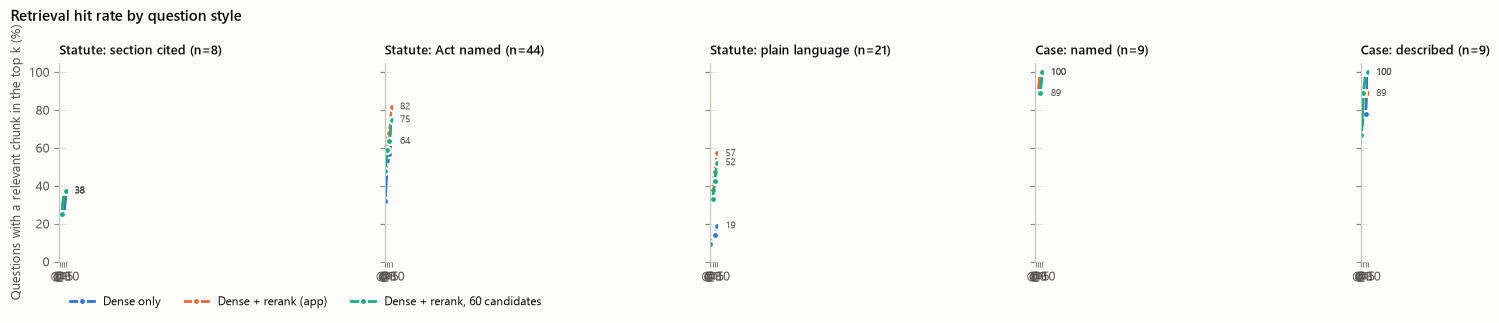

Saved notebooks/results/fig2_retrieval_hit_rate.png
23 questions with no relevant chunk in the app's top 10:


,id,style,question,in_pool_30,top3_app
0,s01,act,"What is the punishment for murder under the Bharatiya Nyaya Sanhita, 2023?",False,"The Bharatiya Nyaya Sanhita, 2023 s.200 | The Bharatiya Nagarik Suraksha San..."
1,s02,plain,Someone tricked my father into handing over his savings by pretending to be ...,False,S_2004_1_601_603_EN | cghc010421572025_1_2025-12-05 | 2018_12_857_867_EN
8,s09,plain,I am afraid the police will arrest me in a false non-bailable case. Under th...,False,"The Code of Criminal Procedure Act s.437 | Code of Criminal Procedure, 1973 ..."
10,s11,act,When can the police arrest a person without a warrant under the BNSS?,False,hcbm040127902025_1_2025-08-22 | hcbm040052032025_1_2025-04-16 | hcbm04001787...
11,s12,act,"Under the BNSS, can a wife claim maintenance from a husband who neglects her?",True,cghc010228972026_1_2026-06-30 | 1987_2_773_784_EN | cghc010225652022_1_2025-...
15,s16,section,What does Section 420 IPC deal with?,False,hcbm030254092018_1_2018-09-25 | cghc010090642016_1_2016-06-17 | cghc01027540...
16,s17,section,Explain Section 498A of the Indian Penal Code.,False,cghc010221462024_1_2026-08-14 | orders_2025_233300019802025_2 | orders_2024_...
19,s20,section,What does Section 438 of the Code of Criminal Procedure provide?,False,"The Code of Criminal Procedure (Amendment) Act, 2005 s.34 | hcbm010416762009..."
20,s21,act,"How is an FIR registered under the Code of Criminal Procedure, 1973?",True,cghc010132742018_1_2023-04-17 | hcbm010151542012_1_2013-11-28 | 2012_1_1066_...
21,s22,section,Who can claim maintenance under Section 125 CrPC?,False,cghc010340542023_1_2024-01-18 | cghc010270962015_1_2017-02-09 | cghc01009488...


In [15]:
if RUN["retrieval"]:
    fig, axes = plt.subplots(1, len(GROUPS), figsize=(14, 3.3), sharey=True)
    for ax, g in zip(axes, GROUPS):
        sub = ret[(ret.kind == g[0]) & (ret["style"] == g[1])]
        for i, system in enumerate(SYSTEMS):
            ys = [hit_metrics(sub, system)[f"Hit@{k}"] for k in KS]
            ax.plot(range(len(KS)), ys, color=SERIES[i], lw=2, marker="o", ms=5, markeredgecolor=INK["surface"], markeredgewidth=1.5, label=system)
            ax.annotate(f"{ys[-1]:.0f}", (len(KS) - 1, ys[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=7.5, color=INK["secondary"])
        ax.set_xticks(range(len(KS)), [f"@{k}" for k in KS])
        ax.set_title(f"{GROUP_LABEL[g]} (n={len(sub)})", fontsize=9)
        ax.set_ylim(0, 105)
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("Questions with a relevant chunk in the top k (%)")
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3)
    fig.suptitle("Retrieval hit rate by question style", x=0.01, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout()
    save_fig(fig, "fig2_retrieval_hit_rate.png")

    misses = ret[ret["rank::" + SYSTEMS[1]].isna()][["id", "style", "question", "in_pool_30", "top3_app"]]
    print(f"{len(misses)} questions with no relevant chunk in the app's top 10:")
    display(misses)

## 3. Routing and drafting classification

`src/routing.py` sends each question to the legal corpus (`LOCAL`), the web (`WEB`) or both (`BOTH`). Advice scenarios may go to either `LOCAL` or `BOTH` (both search the corpus); non-legal questions must go to `WEB`. The most consequential decision is whether the corpus is searched at all, reported separately. Regex fast paths decide most questions; the rest go to an LLM (Gemini when `GEMINI_API_KEY` is set, else the local model), counted here.

Drafting requests are detected by `is_drafting_request` and given a format by `classify_document`. The README's own examples (which the patterns were written against) are reported separately from paraphrases.

In [16]:
INTENTS = ["STATUTE", "PRECEDENT", "GENERAL_ADVICE", "CURRENT_INFORMATION", "GENERAL_KNOWLEDGE", "UNKNOWN"]

def classify_counting(question):
    calls = []
    original = routing._call_llm
    routing._call_llm = lambda prompt: (calls.append(1), original(prompt))[1]
    try:
        t0 = time.time()
        r = routing.classify_query(question)
        return r, bool(calls), time.time() - t0
    finally:
        routing._call_llm = original

if RUN["routing"]:
    rows = []
    labelled = [dict(r, group="routing set") for r in BENCH["routing"]] + \
               [{"id": q["id"], "question": q["question"], "intent": None, "sources": ["LOCAL", "BOTH"], "group": f"{q['kind']} questions"} for q in CORPUS_ITEMS]
    for item in tqdm(labelled, desc="Routing"):
        r, used_llm, secs = classify_counting(item["question"])
        expect_corpus = any(s in ("LOCAL", "BOTH") for s in item["sources"])
        rows.append({"id": item["id"], "group": item["group"], "question": item["question"],
                     "expected_intent": item["intent"], "predicted_intent": r["intent"],
                     "expected_sources": "/".join(item["sources"]), "predicted_source": r["source"],
                     "source_ok": r["source"] in item["sources"],
                     "corpus_decision_ok": (r["source"] in ("LOCAL", "BOTH")) == expect_corpus,
                     "intent_ok": None if item["intent"] is None else r["intent"] == item["intent"],
                     "used_llm": used_llm, "seconds": round(secs, 3), "reasoning": r["reasoning"]})
    rt = pd.DataFrame(rows)
    save_csv(rt, "part3_routing_per_question.csv")

    rs = rt[rt.group == "routing set"].copy()
    rs["intent_ok"] = rs.intent_ok.astype(bool)
    by_intent = rs.groupby("expected_intent").agg(n=("id", "size"), intent_acc=("intent_ok", "mean"), source_acc=("source_ok", "mean"),
                                                  llm_fallback=("used_llm", "mean"))
    by_intent[["intent_acc", "source_acc", "llm_fallback"]] *= 100
    routing_summary = {
        "routing_set_n": len(rs),
        "intent_accuracy_%": 100 * rs.intent_ok.mean(),
        "source_accuracy_%": 100 * rs.source_ok.mean(),
        "corpus_decision_accuracy_%": 100 * rs.corpus_decision_ok.mean(),
        "corpus_questions_searched_corpus_%": 100 * rt[rt.group != "routing set"].corpus_decision_ok.mean(),
        "llm_fallback_%": 100 * rt.used_llm.mean(),
        "median_ms_fast_path": 1000 * rt[~rt.used_llm].seconds.median(),
        "median_ms_llm_path": 1000 * rt[rt.used_llm].seconds.median() if rt.used_llm.any() else None,
    }
    save_csv(by_intent, "part3_routing_by_intent.csv", index=True)
    display(by_intent.round(1))
    display(pd.Series(routing_summary).round(1))
    display(rt[~rt.source_ok | (rt.intent_ok == False)][["id", "group", "question", "expected_intent", "predicted_intent", "expected_sources", "predicted_source"]])

Routing: 100%|██████████| 126/126 [00:16<00:00,  7.46it/s]


,n,intent_acc,source_acc,llm_fallback
expected_intent,,,,
CURRENT_INFORMATION,4,50.0,50.0,25.0
GENERAL_ADVICE,8,100.0,100.0,12.5
GENERAL_KNOWLEDGE,9,100.0,100.0,33.3
PRECEDENT,6,100.0,100.0,0.0
STATUTE,8,100.0,100.0,0.0


routing_set_n                           35.0
intent_accuracy_%                       94.3
source_accuracy_%                       94.3
corpus_decision_accuracy_%             100.0
corpus_questions_searched_corpus_%     100.0
llm_fallback_%                           5.6
median_ms_fast_path                      0.0
median_ms_llm_path                    2371.0
dtype: float64

,id,group,question,expected_intent,predicted_intent,expected_sources,predicted_source
22,r23,routing set,What are the latest Supreme Court judgments on bail this month?,CURRENT_INFORMATION,PRECEDENT,BOTH,LOCAL
23,r24,routing set,Has the government notified any new amendment to the BNSS recently?,CURRENT_INFORMATION,STATUTE,BOTH,LOCAL


findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: 

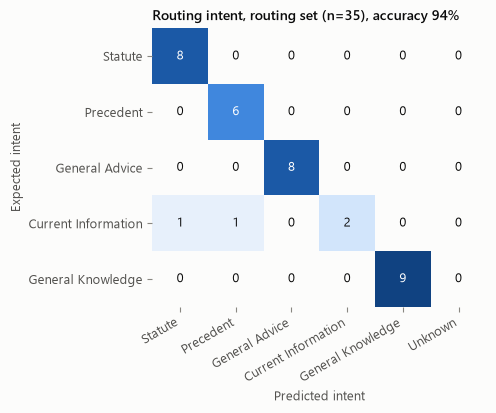

Saved notebooks/results/fig3_routing_confusion.png


In [17]:
if RUN["routing"]:
    from matplotlib.colors import LinearSegmentedColormap
    cm = pd.crosstab(pd.Categorical(rs.expected_intent, INTENTS[:-1]), pd.Categorical(rs.predicted_intent, INTENTS), dropna=False)
    cm = cm.loc[[i for i in INTENTS[:-1] if i in cm.index]]
    seq = LinearSegmentedColormap.from_list("blue_seq", [INK["surface"], "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.imshow(cm.values, cmap=seq, vmin=0, vmax=max(1, cm.values.max()))
    for (i, j), v in np.ndenumerate(cm.values):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=9, color="#ffffff" if v > cm.values.max() * 0.55 else INK["primary"])
    nice = lambda s: s.replace("_", " ").title()
    ax.set_xticks(range(len(cm.columns)), [nice(c) for c in cm.columns], rotation=30, ha="right")
    ax.set_yticks(range(len(cm.index)), [nice(c) for c in cm.index])
    ax.set_xlabel("Predicted intent"); ax.set_ylabel("Expected intent")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(f"Routing intent, routing set (n={len(rs)}), accuracy {rs.intent_ok.mean():.0%}")
    fig.tight_layout()
    save_fig(fig, "fig3_routing_confusion.png")

In [18]:
if RUN["routing"]:
    drows = []
    for d in BENCH["drafting"]:
        detected = is_drafting_request(d["question"])
        drows.append({"id": d["id"], "set": d["set"], "question": d["question"], "expected_format": d["format"],
                      "detected": detected, "predicted_format": classify_document(d["question"]) if detected else None})
    dr = pd.DataFrame(drows)
    dr["format_ok"] = dr.predicted_format == dr.expected_format
    negatives = [r["question"] for r in BENCH["routing"]] + [q["question"] for q in CORPUS_ITEMS]
    false_pos = [q for q in negatives if is_drafting_request(q)]
    draft_summary = dr.groupby("set").agg(n=("id", "size"), detected_pct=("detected", "mean"), correct_format_pct=("format_ok", "mean"))
    draft_summary[["detected_pct", "correct_format_pct"]] *= 100
    draft_summary.loc["false positives (non-drafting questions)", ["n", "detected_pct"]] = [len(negatives), 100 * len(false_pos) / len(negatives)]
    save_csv(dr, "part3_drafting_per_request.csv")
    save_csv(draft_summary, "part3_drafting_summary.csv", index=True)
    display(draft_summary.round(1))
    display(dr[~dr.format_ok])
    if false_pos:
        print("Flagged as drafting but are not:", false_pos)

,n,detected_pct,correct_format_pct
set,,,
paraphrase,4.0,50.0,50.0
readme,15.0,100.0,100.0
false positives (non-drafting questions),126.0,0.8,NaN


,id,set,question,expected_format,detected,predicted_format,format_ok
16,d17,paraphrase,Write up a demand letter to my former employer for my unpaid salary,legal_notice,False,NaN,False
17,d18,paraphrase,Help me file an RTI to get a copy of my exam answer sheet,rti_application,False,NaN,False


Flagged as drafting but are not: ['I bought a defective phone and the seller refuses to replace it. Where and how can I file a consumer complaint?']


## 4. Evidence thresholds

`src/pipeline.py` uses the top cross-encoder score of the local evidence to decide: at or above **3** the corpus alone answers, below **-2** the corpus is ignored for the web, in between both are used. This plots the top score for questions the corpus covers (coloured by whether a relevant chunk actually reached the top 5), legal advice scenarios, and non-legal questions.

decision,local + web,local only (>= 3),web only (< -2)
group,,,
Advice scenarios,7,0,1
Case: described,2,7,0
Case: named,0,9,0
Non-legal questions,2,0,7
Statute: Act named,0,44,0
Statute: plain language,10,11,0
Statute: section cited,0,8,0


findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: 

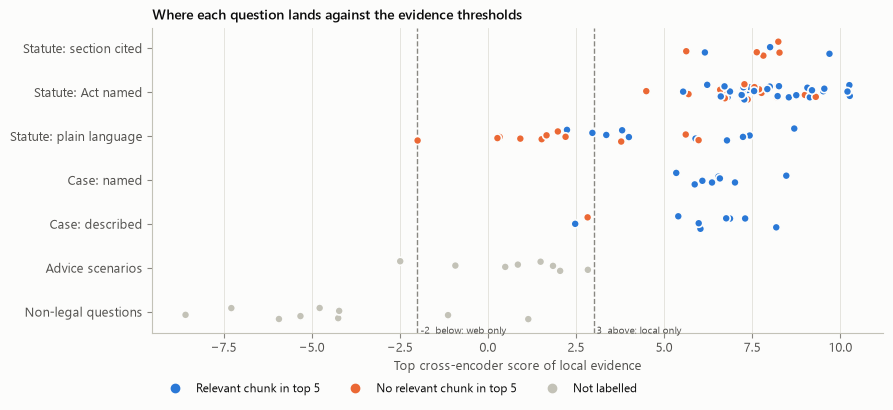

Saved notebooks/results/fig4_evidence_thresholds.png


In [19]:
if RUN["retrieval"]:
    extra = [r for r in BENCH["routing"] if r["intent"] in ("GENERAL_ADVICE", "GENERAL_KNOWLEDGE")]
    srows = [{"group": GROUP_LABEL[(row.kind, row["style"])], "id": row.id, "top_score": row.top_rerank_score,
              "relevant_in_top5": bool(row["rank::" + SYSTEMS[1]] <= 5)} for _, row in ret.iterrows()]
    for r in extra:
        q = pipeline.retrieval_query(r["question"])
        top = reranker.rerank(q, retriever.search(q, top_k=20), top_k=1)
        srows.append({"group": "Advice scenarios" if r["intent"] == "GENERAL_ADVICE" else "Non-legal questions",
                      "id": r["id"], "top_score": top[0]["rerank_score"] if top else None, "relevant_in_top5": None})
    sc = pd.DataFrame(srows)
    bucket = lambda s: "local only (>= 3)" if s >= pipeline.LOCAL_STRONG else ("web only (< -2)" if s < pipeline.LOCAL_IRRELEVANT else "local + web")
    sc["decision"] = sc.top_score.map(bucket)
    save_csv(sc, "part4_top_scores.csv")
    decision_table = pd.crosstab(sc.group, sc.decision)
    save_csv(decision_table, "part4_decisions.csv", index=True)
    display(decision_table)

    order = [GROUP_LABEL[g] for g in GROUPS] + ["Advice scenarios", "Non-legal questions"]
    rng = np.random.default_rng(SEED)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for yi, g in enumerate(order):
        sub = sc[sc.group == g]
        jitter = rng.uniform(-0.18, 0.18, len(sub))
        colors = [NEUTRAL if r is None else (SERIES[0] if r else SERIES[1]) for r in sub.relevant_in_top5]
        ax.scatter(sub.top_score, np.full(len(sub), yi) + jitter, s=34, c=colors, edgecolors=INK["surface"], linewidths=1.2, zorder=3)
    for x, label in [(pipeline.LOCAL_IRRELEVANT, "below: web only"), (pipeline.LOCAL_STRONG, "above: local only")]:
        ax.axvline(x, color=INK["muted"], lw=1, ls="--", zorder=1)
        ax.text(x, len(order) - 0.45, f" {x:g}  {label}", fontsize=7.5, color=INK["secondary"], va="bottom")
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.set_xlabel("Top cross-encoder score of local evidence")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker="o", ls="", color=c, markersize=6, label=l) for c, l in
               [(SERIES[0], "Relevant chunk in top 5"), (SERIES[1], "No relevant chunk in top 5"), (NEUTRAL, "Not labelled")]]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)
    ax.set_title("Where each question lands against the evidence thresholds")
    fig.tight_layout()
    save_fig(fig, "fig4_evidence_thresholds.png")

## 5. End-to-end answers: base vs fine-tuned, with and without retrieval

Each model answers every corpus question twice: **closed-book** (the question alone) and **with retrieval** (the app's prompt from `src/generation.py` with the evidence `src/pipeline.py` would pass: chunks scoring at least 0, up to 5). Web search is not used, so this isolates the local corpus.

- **Correct provision** (statute questions): the answer names a target section and its Act.
- **Case named** (landmark-case questions): the answer names the expected case.
- **Citations not in evidence** (with retrieval): share of the section numbers an answer cites that appear neither as a retrieved section nor in the retrieved text. A proxy for fabricated citations; lower is better.

In [20]:
def pick_corpus_items():
    if N_CORPUS is None:
        return CORPUS_ITEMS
    n_st, n_pr = N_CORPUS
    return [q for q in CORPUS_ITEMS if q["kind"] == "statute"][:n_st] + [q for q in CORPUS_ITEMS if q["kind"] == "precedent"][:n_pr]

def pipeline_evidence(ranked, k=5):
    """The local evidence src/pipeline.py hands the model (without web)."""
    if not ranked:
        return []
    relevant = [c for c in ranked if c["rerank_score"] >= pipeline.CHUNK_MIN_SCORE][:k]
    return relevant or (ranked[:3] if ranked[0]["rerank_score"] >= pipeline.LOCAL_IRRELEVANT else [])

def evidence_sections(chunks):
    secs = {norm_sec(c["section_number"]) for c in chunks if c.get("source_type") == "act" and c.get("section_number")}
    for c in chunks:
        secs |= cited_sections(c.get("text"))
    return secs

if RUN["rag_answers"]:
    E2E = pick_corpus_items()
    ROUTE = {q["id"]: routing.classify_query(q["question"]) for q in E2E}
    EVIDENCE = {q["id"]: pipeline_evidence(RANKED[q["id"]]) for q in E2E}
    prompts = []
    for q in E2E:
        r = ROUTE[q["id"]]
        prompts.append((f"closed|{q['id']}", q["question"]))
        prompts.append((f"rag|{q['id']}", build_prompt(q["question"], EVIDENCE[q["id"]][:pipeline.MAX_CONTEXT], intent=r["intent"], source=r["source"])))
    e2e_cache = Cache(f"answers_t{ANSWER_MAX_TOKENS}_seed{SEED}")
    e2e_gens = run_generations(e2e_cache, prompts, ANSWER_MAX_TOKENS, "Answers")

    rows = []
    for q in E2E:
        ev = EVIDENCE[q["id"]]
        rel = is_relevant(q)
        ev_secs = evidence_sections(ev)
        for m in MODELS:
            for cond in ["closed", "rag"]:
                g = e2e_gens[(m, f"{cond}|{q['id']}")]
                text = g["text"]
                cited = cited_sections(text)
                row = {"id": q["id"], "kind": q["kind"], "style": q["style"], "model": m, "label": short(m),
                       "condition": "Closed-book" if cond == "closed" else "With retrieval",
                       "evidence_has_answer": any(rel(c) for c in ev), "n_evidence": len(ev),
                       "n_cited_sections": len(cited), "completion_tokens": g["completion_tokens"],
                       "latency_s": g["latency_s"], "hit_max_tokens": g["finish"] == "length", "answer": text}
                if q["kind"] == "statute":
                    row["correct_provision"] = cites_provision(text, q["targets"])
                    row["act_named"] = any(mentions_act(text, k) for k, _ in q["targets"])
                else:
                    row["case_named"] = bool(re.search(q["pattern"], text, re.I))
                if cond == "rag" and cited:
                    row["unsupported_citation_rate"] = len(cited - ev_secs) / len(cited)
                rows.append(row)
    e2e = pd.DataFrame(rows)
    for col in ["correct_provision", "act_named", "case_named"]:
        if col in e2e:
            e2e[col] = e2e[col].astype(float)  # 1/0, NaN where the metric does not apply
    save_csv(e2e, "part5_answers_per_question.csv")

Answers: 4B Base:   0%|          | 0/182 [00:00<?, ?it/s]

Starting llama-server with qwen3-vl-4b-instruct.Q4_K_M.gguf ...


Answers: 4B Fine-tuned:   0%|          | 0/182 [00:00<?, ?it/s]

Starting llama-server with legal-qwen3-vl-4b.Q4_K_M.gguf ...


Answers: 8B Base:   0%|          | 0/182 [00:00<?, ?it/s]

Starting llama-server with qwen3-vl-8b-instruct.Q4_K_M.gguf ...


Answers: 8B Fine-tuned:   0%|          | 0/182 [00:00<?, ?it/s]

Starting llama-server with legal-qwen3-vl-8b.Q4_K_M.gguf ...


Answers: 8B Fine-tuned: 100%|██████████| 182/182 [25:03<00:00,  8.26s/it]


In [21]:
if RUN["rag_answers"]:
    def pct(s):
        s = s.dropna()
        return 100 * s.astype(float).mean() if len(s) else np.nan

    agg = []
    for (label, cond), sub in e2e.groupby(["label", "condition"], sort=False):
        st, pr = sub[sub.kind == "statute"], sub[sub.kind == "precedent"]
        agg.append({"model": label, "condition": cond,
                    "correct_provision_%": pct(st.correct_provision) if len(st) else np.nan,
                    "correct_provision_when_evidence_has_it_%": pct(st[st.evidence_has_answer].correct_provision) if len(st) else np.nan,
                    "act_named_%": pct(st.act_named) if len(st) else np.nan,
                    "case_named_%": pct(pr.case_named) if len(pr) else np.nan,
                    "citations_not_in_evidence_%": pct(sub.unsupported_citation_rate) if cond == "With retrieval" else np.nan,
                    "answer_tokens": sub.completion_tokens.mean(), "latency_s": sub.latency_s.mean(),
                    "hit_max_tokens_%": pct(sub.hit_max_tokens)})
    e2e_summary = pd.DataFrame(agg).set_index(["model", "condition"])
    save_csv(e2e_summary, "part5_answers_summary.csv", index=True)
    by_style = e2e[e2e.kind == "statute"].pivot_table(index=["label", "condition"], columns="style", values="correct_provision", aggfunc="mean") * 100
    save_csv(by_style, "part5_correct_provision_by_style.csv", index=True)
    display(e2e_summary.round(1))
    display(by_style.round(1))

correct_provision_%  \
model         condition                             
4B Base       Closed-book                    46.6   
              With retrieval                 89.0   
4B Fine-tuned Closed-book                    13.7   
              With retrieval                 86.3   
8B Base       Closed-book                    54.8   
              With retrieval                 91.8   
8B Fine-tuned Closed-book                    19.2   
              With retrieval                 87.7   

                              correct_provision_when_evidence_has_it_%  \
model         condition                                                  
4B Base       Closed-book                                         48.8   
              With retrieval                                     100.0   
4B Fine-tuned Closed-book                                          9.3   
              With retrieval                                      97.7   
8B Base       Closed-book                                         55.8   
              With retrieval                                     100.0   
8B Fine-tuned Closed-book                                         16.3   
              With retrieval                                      95.3   

                              act_named_%  case_named_%  \
model         condition                                   
4B Base       Closed-book            82.2          61.1   
              With retrieval         94.5          83.3   
4B Fine-tuned Closed-book            68.5          72.2   
              With retrieval         91.8          88.9   
8B Base       Closed-book            84.9          77.8   
              With retrieval         97.3          88.9   
8B Fine-tuned Closed-book            69.9          77.8   
              With retrieval         95.9          88.9   

                              citations_not_in_evidence_%  answer_tokens  \
model         condition                                                    
4B Base       Closed-book                             NaN          682.3   
              With retrieval                          3.5          753.6   
4B Fine-tuned Closed-book                             NaN          268.9   
              With retrieval                          6.7          474.0   
8B Base       Closed-book                             NaN          640.4   
              With retrieval                          6.9          754.9   
8B Fine-tuned Closed-book                             NaN          288.9   
              With retrieval                          2.0          629.3   

                              latency_s  hit_max_tokens_%  
model         condition                                    
4B Base       Closed-book           7.1              50.5  
              With retrieval        9.2              83.5  
4B Fine-tuned Closed-book           2.8               0.0  
              With retrieval        5.9               0.0  
8B Base       Closed-book          10.3              33.0  
              With retrieval       13.9              82.4  
8B Fine-tuned Closed-book           4.7               0.0  
              With retrieval       11.7              37.4

style                          act  plain  section
label         condition                           
4B Base       Closed-book     45.5   28.6    100.0
              With retrieval  93.2   76.2    100.0
4B Fine-tuned Closed-book      6.8    4.8     75.0
              With retrieval  93.2   66.7    100.0
8B Base       Closed-book     61.4   23.8    100.0
              With retrieval  97.7   76.2    100.0
8B Fine-tuned Closed-book     13.6    4.8     87.5
              With retrieval  95.5   66.7    100.0

findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: Font family 'system-ui' not found.
findfont: 

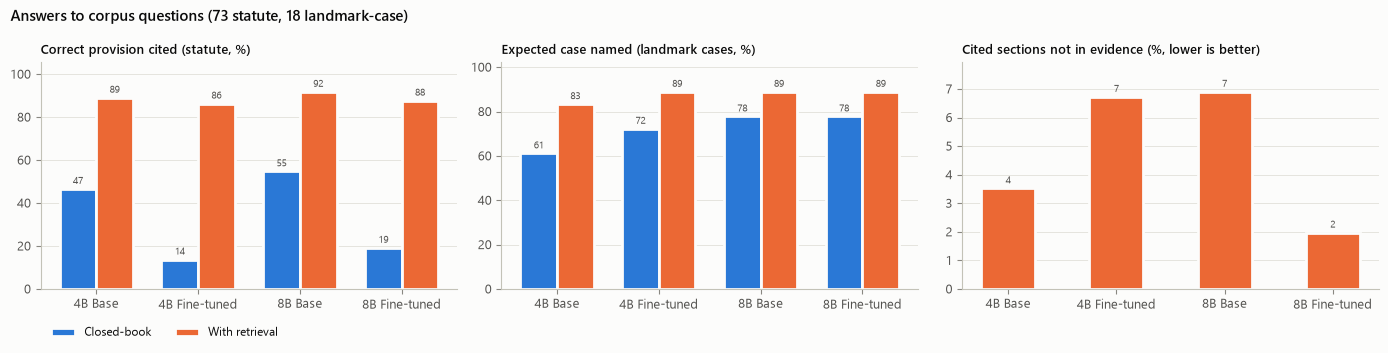

Saved notebooks/results/fig5_answers.png


In [22]:
if RUN["rag_answers"]:
    labels = [short(m) for m in MODELS]
    panels = [("correct_provision_%", "Correct provision cited (statute, %)", ["Closed-book", "With retrieval"]),
              ("case_named_%", "Expected case named (landmark cases, %)", ["Closed-book", "With retrieval"]),
              ("citations_not_in_evidence_%", "Cited sections not in evidence (%, lower is better)", ["With retrieval"])]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, (col, title, conds) in zip(axes, panels):
        vals = {c: {l: e2e_summary.loc[(l, c), col] for l in labels} for c in conds}
        width = 0.36 if len(conds) == 2 else 0.5
        x = np.arange(len(labels))
        offs = (np.arange(len(conds)) - (len(conds) - 1) / 2) * width
        for i, c in enumerate(conds):
            color = SERIES[["Closed-book", "With retrieval"].index(c)]
            bars = ax.bar(x + offs[i], [vals[c][l] for l in labels], width, color=color, edgecolor=INK["surface"], linewidth=2, label=c)
            label_bars(ax, bars, "{:.0f}")
        ax.set_xticks(x, labels)
        ax.set_title(title, fontsize=9.5)
        ax.margins(y=0.15)
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
    n_st = (e2e.kind == "statute").sum() // (2 * len(MODELS)); n_pr = (e2e.kind == "precedent").sum() // (2 * len(MODELS))
    fig.suptitle(f"Answers to corpus questions ({n_st} statute, {n_pr} landmark-case)", x=0.01, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout()
    save_fig(fig, "fig5_answers.png")

In [23]:
if RUN["rag_answers"]:
    lines = ["# Answer examples (closed-book vs with retrieval)\n"]
    for q in E2E[:2] + [x for x in E2E if x["kind"] == "precedent"][:1]:
        lines.append(f"## {q['question']}\n")
        lines.append("Evidence: " + "; ".join(f"{c.get('paper_title')} s.{c.get('page')} ({c['rerank_score']:.1f})" for c in EVIDENCE[q["id"]]) + "\n")
        for m in MODELS:
            for cond in ["closed", "rag"]:
                answer = e2e_gens[(m, f"{cond}|{q['id']}")]["text"][:900]
                lines.append(f"**{short(m)}, {'closed-book' if cond == 'closed' else 'with retrieval'}:** {answer}\n")
    (RESULTS / "examples_answers.md").write_text("\n".join(lines), encoding="utf-8")
    print("Saved notebooks/results/examples_answers.md")

Saved notebooks/results/examples_answers.md


### 5b. LLM judge (optional, off by default)

Grades each statute answer from 1 to 5 against the text of the target section (taken from the index), with Gemini. Enable with `RUN["judge"] = True`; it makes one API call per answer (about 580 for the full set) and is cached.

In [24]:
JUDGE_PROMPT = """You are grading an answer to an Indian law question against the governing provision.

QUESTION:
{question}

GOVERNING PROVISION(S):
{provision}

ANSWER:
{answer}

Score 1-5 for each:
- correctness: does the answer state the law in the provision accurately (5 = fully correct, 1 = wrong)?
- faithfulness: does it avoid claims that contradict the provision or cite provisions that do not apply (5 = none, 1 = many)?
Return only JSON: {{"correctness": n, "faithfulness": n, "reason": "one sentence"}}"""

judge = None
if RUN["judge"] and RUN["rag_answers"]:
    import lancedb
    acts_tbl = lancedb.connect("data/lancedb").open_table("acts")
    def provision_text(targets):
        out = []
        for key, sec in targets:
            for r in acts_tbl.search().where(f"section_number = '{sec}'").select(["act_title", "text"]).limit(5000).to_list():
                if _title_ok(r["act_title"], key):
                    out.append(r["text"][:2500])
                    break
        return "\n\n".join(out)
    j_cache = Cache("judge_gemini")
    jrows = []
    for q in tqdm([x for x in E2E if x["kind"] == "statute"], desc="Judge"):
        prov = provision_text(q["targets"])
        for m in MODELS:
            for cond in ["closed", "rag"]:
                key = f"{m}|{cond}|{q['id']}"
                if j_cache.get(key) is None:
                    raw = llm._call_gemini_api(JUDGE_PROMPT.format(question=q["question"], provision=prov, answer=e2e_gens[(m, f"{cond}|{q['id']}")]["text"]),
                                               model_id="gemini-3.8-flash", max_tokens=200, temperature=0.0, thinking_budget=0)
                    mt = re.search(r"\{[\s\S]*\}", raw)
                    j_cache.put(key, json.loads(mt.group(0)) if mt else {"correctness": None, "faithfulness": None, "reason": raw[:200]})
                jrows.append({"id": q["id"], "model": short(m), "condition": "Closed-book" if cond == "closed" else "With retrieval", **j_cache.get(key)})
    judge = pd.DataFrame(jrows)
    save_csv(judge, "part5b_judge_per_answer.csv")
    judge_summary = judge.groupby(["model", "condition"], sort=False)[["correctness", "faithfulness"]].mean()
    save_csv(judge_summary, "part5b_judge_summary.csv", index=True)
    display(judge_summary.round(2))
else:
    print("Skipped (RUN['judge'] is False).")

Skipped (RUN['judge'] is False).


## Summary and report

In [25]:
llm._stop_llama_server()
ENV["run_finished"] = time.strftime("%Y-%m-%d %H:%M:%S")
(RESULTS / "environment.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")

parts = [f"# Evaluation report\n\nRun {ENV['run_started']} to {ENV['run_finished']} on {ENV['gpu']} "
         f"({'QUICK mode' if QUICK else 'full run'}), llama.cpp {ENV['llama_server']}, context {ENV['context_window']}, seed {SEED}. "
         f"Generated by `notebooks/evaluation.ipynb`; per-question data in the CSVs next to this file.\n"]
summary = {"environment": ENV}

if RUN["model_quality"]:
    parts.append(f"## 1. Model quality without retrieval ({len(heldout)} held-out questions)\n\n![](fig1_model_quality.png)\n\n"
                 + md_table(mq_summary[["rouge_1", "rouge_2", "rouge_l", "bleu_4", "citation_f1", "legal_terms", "gen_tok_s", "latency_s"]]) +
                 "\n\nFine-tuned minus base (95% paired bootstrap interval):\n\n" +
                 md_table(mq_delta[["size", "metric", "base", "fine_tuned", "difference", "ci95_low", "ci95_high", "significant"]], index=False) +
                 "\n\nDifference from the bf16 HPC reference (FINETUNING_INFO.md, section 8):\n\n" +
                 md_table(ref_cmp.pivot(index="model", columns="metric", values="difference")))
    summary["model_quality"] = mq_summary.round(3).to_dict(orient="index")
    summary["finetune_effect"] = mq_delta.round(3).to_dict(orient="records")
if ppl is not None:
    parts.append("### Perplexity on the reference answers\n\n" + md_table(ppl, fmt="{:.3f}"))
    summary["perplexity"] = ppl.round(4).to_dict(orient="index")
if RUN["retrieval"]:
    parts.append("## 2. Retrieval\n\n![](fig2_retrieval_hit_rate.png)\n\n" + md_table(ret_summary, index=False))
    summary["retrieval"] = ret_summary.round(3).to_dict(orient="records")
if RUN["routing"]:
    parts.append("## 3. Routing and drafting\n\n![](fig3_routing_confusion.png)\n\n" + md_table(by_intent) + "\n\n" +
                 md_table(pd.Series(routing_summary, name="value").to_frame()) + "\n\nDrafting requests:\n\n" + md_table(draft_summary))
    summary["routing"] = routing_summary
    summary["drafting"] = draft_summary.round(2).to_dict(orient="index")
if RUN["retrieval"]:
    parts.append("## 4. Evidence thresholds\n\n![](fig4_evidence_thresholds.png)\n\n" + md_table(decision_table, fmt="{:.0f}"))
    summary["evidence_decisions"] = decision_table.to_dict(orient="index")
if RUN["rag_answers"]:
    parts.append("## 5. End-to-end answers\n\n![](fig5_answers.png)\n\n" + md_table(e2e_summary) +
                 "\n\nCorrect provision by question style (%):\n\n" + md_table(by_style))
    summary["answers"] = {f"{k[0]} | {k[1]}": v for k, v in e2e_summary.round(3).to_dict(orient="index").items()}
if judge is not None:
    parts.append("### LLM judge (Gemini, 1-5)\n\n" + md_table(judge_summary))
    summary["judge"] = {f"{k[0]} | {k[1]}": v for k, v in judge_summary.round(3).to_dict(orient="index").items()}

parts.append("## Method notes\n\n"
             "- All local generation uses the deployed Q4_K_M GGUFs through llama-server, temperature 0.2, top-p 0.9, repetition penalty 1.1, fixed seed. "
             f"Part 1 answers are capped at {CLOSED_BOOK_MAX_TOKENS} tokens like the reference benchmark; part 5 at {ANSWER_MAX_TOKENS} (the app allows 1500).\n"
             "- Overlap metrics (ROUGE, BLEU, citation F1) are computed with the reference benchmark's code (`to_finetune/evaluate.py`).\n"
             "- Statute targets were verified against the index; landmark-case relevance is a text match on case name plus subject keyword, so a chunk that only cites the case counts.\n"
             "- 'Correct provision' needs both the section number and the Act in the answer; 'citations not in evidence' is a regex proxy and can flag sections the model cited correctly from memory.\n"
             "- Web search is not used anywhere; part 5 measures the local corpus only.\n")
(RESULTS / "report.md").write_text("\n\n".join(parts), encoding="utf-8")
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("Wrote notebooks/results/report.md and summary.json")
print(sorted(p.name for p in RESULTS.iterdir() if p.is_file()))

Wrote notebooks/results/report.md and summary.json
['environment.json', 'examples_answers.md', 'examples_heldout.md', 'fig1_model_quality.png', 'fig2_retrieval_hit_rate.png', 'fig3_routing_confusion.png', 'fig4_evidence_thresholds.png', 'fig5_answers.png', 'part1_finetune_effect.csv', 'part1_heldout_per_question.csv', 'part1_heldout_summary.csv', 'part1_vs_reference.csv', 'part2_retrieval_per_question.csv', 'part2_retrieval_summary.csv', 'part2_retrieved_top5.jsonl', 'part3_drafting_per_request.csv', 'part3_drafting_summary.csv', 'part3_routing_by_intent.csv', 'part3_routing_per_question.csv', 'part4_decisions.csv', 'part4_top_scores.csv', 'part5_answers_per_question.csv', 'part5_answers_summary.csv', 'part5_correct_provision_by_style.csv', 'report.md', 'summary.json']
